# Color classes (sand, whitewater, water) to put the SAM waterline at the beach edge
csherwood@usgs.gov, 2026-10-28, generated with Claude Opus 5.5

SAM tends to stop at the outer edge of the surf zone: to it, whitewater and blue water look like different
objects, so prompts in blue water give a mask of blue water only. Following CoastSat (Vos et al., 2019a, b),
pixels are classified as **sand**, **whitewater** or **water**, and the waterline is the boundary between sand and
whitewater plus water. The classifier is a Gaussian (quadratic discriminant) model on lighting-insensitive
features: chromaticity r = R/(R+G+B), g = G/(R+G+B), and log brightness relative to the median inside the prompt
polygon. You train it by clicking examples of each class on a few images.

The model is then used three ways (`marconi_sam`, `marconi_color`):
* **per-image prompts:** foreground points on the wet side and background points on the sand side, 6 to 30
  pixels (at half resolution) from that image's own color boundary, spread along the beach, in addition to
  your hand-clicked polygon points;
* **mask choice:** of SAM's three candidate masks, the one that best matches the color classes (intersection
  over union of the wet region inside the polygon) is kept, instead of the one SAM scores highest;
* **color waterline:** the sand/wet boundary itself, a third method that runs without a GPU (about 0.1 s per image).

**Labeling:** for each image, click **SAND** points (dry and wet sand, including dark wet sand in the swash), then
**WHITEWATER** points (foam in the surf and swash), then **WATER** points (unbroken water, including glassy or dark
water), pressing **Enter** after each class. Click inside the white dashed polygon, since that is where the model is
used. Spread clicks along the beach; 5–15 per class per image is plenty. If a class is absent (no whitewater on a
calm day), just press Enter. Otsu (red) and SAM (cyan) waterlines are drawn for reference. Labels are saved after
each image, so you can stop and rerun; delete rows from `COLOR_LABELS` to redo an image.

Needs `sam_prompts.csv` (from `sam_prompts.ipynb`) and an interactive backend for clicking (`%matplotlib qt`).

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import marconi_sam as msam
import marconi_color as mc

# --- config
PROJ = Path(r'F:\crs\proj\2026_wl_dems')
CAL_DIR = Path(r'F:\crs\proj\marconi_imagery\calibration_parameters')
OUT_DIR = PROJ / 'scan'
SCAN_CSV = OUT_DIR / 'image_scan.csv'
WL_CSV = OUT_DIR / 'waterlines_px.csv'                 # Otsu
WL_SAM_CSV = OUT_DIR / 'waterlines_px_sam.csv'         # SAM from qc_waterlines.ipynb (for reference, if present)
COMPARE_CSV = OUT_DIR / 'waterline_compare.csv'        # Otsu vs SAM distances (to pick the worst images)
PROMPT_CSV = OUT_DIR / 'sam_prompts.csv'
COLOR_LABELS = OUT_DIR / 'color_labels.csv'
COLOR_NPZ = OUT_DIR / 'color_model.npz'
WL_COLOR_CSV = OUT_DIR / 'waterlines_px_color.csv'
WL_SAMC_CSV = OUT_DIR / 'waterlines_px_sam_color.csv'
FIG_DIR = PROJ / 'fig'
SAM_CKPT = Path(r'F:\crs\src\wl_dem\sam_vit_h_4b8939.pth')
SAM_MODEL = 'vit_h'
N_WORST = 6                    # worst Otsu-SAM disagreements to label
PER_PERIOD = 3                 # more images per camera/EO period, spread over wave height
N_TEST = 60                    # images for the comparison (same random sample as qc_waterlines.ipynb)
COLOR = mc.COLOR | {}          # e.g. {'p_sand': 0.6, 'band': (4, 20)}

scan = pd.read_csv(SCAN_CSV, parse_dates=['time'])
wl_px = pd.read_csv(WL_CSV).groupby('path')
prompts = msam.read_prompts(PROMPT_CSV)
wl_sam = pd.read_csv(WL_SAM_CSV).groupby('path') if WL_SAM_CSV.exists() else None
ref = [('Otsu', 'r', wl_px)] + ([('SAM', 'c', wl_sam)] if wl_sam is not None else [])
worst = []
if COMPARE_CSV.exists():
    cmp_ = pd.read_csv(COMPARE_CSV)
    worst = cmp_.assign(d=cmp_[['d_otsu_sam_med', 'd_sam_otsu_med']].max(1)).nlargest(N_WORST, 'd').path
imgs = mc.label_images(scan, prompts, worst, PER_PERIOD, COLOR)
imgs[['time', 'camera', 'eo_file', 'quality', 'H0', 'water_level']]

C:\Users\csherwood\AppData\Local\Temp\1\ipykernel_61600\2354504453.py:38: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  worst = cmp_.assign(d=cmp_[['d_otsu_sam_med', 'd_sam_otsu_med']].max(1)).nlargest(N_WORST, 'd').path


,time,camera,eo_file,quality,H0,water_level
0,2024-12-21 16:00:00,c2,CACO03_c2_20241023_EO.yaml,4.0,2.8450,-0.23740
1,2025-01-08 16:00:00,c1,CACO03_c1_20250123_EO.yaml,4.0,1.2820,-0.96250
2,2025-01-10 17:30:00,c2,CACO03_c2_20250123_EO.yaml,4.0,1.5430,-0.77730
3,2025-01-19 16:00:00,c1,CACO03_c1_20250123_EO.yaml,4.0,0.8479,-0.28190
4,2025-02-16 20:30:00,c2,CACO04_c2_20250219_EO.yaml,4.0,2.2650,0.82890
5,2025-02-26 21:00:00,c2,CACO04_c2_20250219_EO.yaml,4.0,0.3181,-1.18300
6,2024-12-14 14:00:00,c1,CACO03_c1_20241023_EO.yaml,4.0,0.3418,1.16000
7,2024-12-19 15:30:00,c1,CACO03_c1_20241023_EO.yaml,4.0,0.8388,-0.05584
8,2024-12-22 20:00:00,c1,CACO03_c1_20241023_EO.yaml,4.0,1.5910,0.57760
9,2025-01-17 14:00:00,c1,CACO03_c1_20250123_EO.yaml,4.0,0.3256,-0.43260


In [2]:
%matplotlib qt
labels = mc.collect_labels(imgs, prompts, COLOR_LABELS, ref, COLOR)

23 of 23 images to label
c2 2024-12-21 16:00:00 {'sand': 67, 'whitewater': 45, 'water': 28}
c1 2025-01-08 16:00:00 {'sand': 60, 'water': 57, 'whitewater': 36}
c2 2025-01-10 17:30:00 {'sand': 88, 'water': 45, 'whitewater': 35}
c1 2025-01-19 16:00:00 {'sand': 62, 'whitewater': 33, 'water': 28}
c2 2025-02-16 20:30:00 {'sand': 44, 'whitewater': 38}
c2 2025-02-26 21:00:00 {'sand': 43, 'water': 26, 'whitewater': 16}
c1 2024-12-14 14:00:00 {'sand': 40, 'water': 33, 'whitewater': 15}
c1 2024-12-19 15:30:00 {'sand': 42, 'water': 39, 'whitewater': 30}
c1 2024-12-22 20:00:00 {'water': 39, 'whitewater': 30, 'sand': 26}
c1 2025-01-17 14:00:00 {'sand': 42, 'water': 33, 'whitewater': 5}
c1 2025-01-19 15:00:00 {'sand': 52, 'water': 32, 'whitewater': 28}
c1 2025-01-20 14:00:00 {'whitewater': 61, 'sand': 45, 'water': 34}
c1 2025-03-04 15:00:00 {'sand': 60, 'water': 26, 'whitewater': 9}
c1 2025-02-11 11:30:00 {'sand': 55, 'water': 13, 'whitewater': 6}
c1 2025-02-16 19:00:00 {'sand': 28, 'whitewater': 23}

KeyboardInterrupt: 

## Fit and check the model
The leave-one-image-out confusion matrix shows how well each class is recognized on images the model did not
see. Sand mistaken for whitewater or water (and the reverse) moves the waterline; whitewater versus water does
not matter, since both count as wet.

In [4]:
%matplotlib inline
labels = pd.read_csv(COLOR_LABELS)
X, y, img_id = mc.sample_labels(labels, prompts, COLOR)
model = mc.fit(X, y, COLOR)
mc.save_model(COLOR_NPZ, model)
print(labels.groupby('cls').size().to_dict(), f'{len(np.unique(img_id))} images, {len(y)} pixels')
mc.cross_validate(X, y, img_id, COLOR).round(3)

{'sand': 1032, 'water': 569, 'whitewater': 538} 21 images, 27807 pixels


predicted,sand,whitewater,water
true,,,
sand,0.582,0.288,0.130
whitewater,0.372,0.491,0.136
water,0.075,0.133,0.791


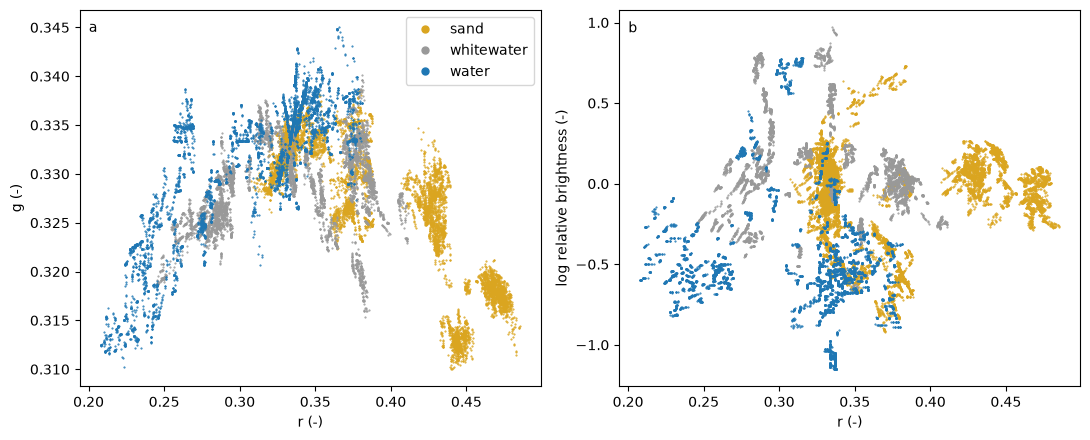

In [5]:
# features of the labeled pixels by class
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for k, (c, col) in enumerate(zip(mc.CLASSES, ['goldenrod', '0.6', 'tab:blue'])):
    ax[0].plot(X[y == k, 0], X[y == k, 1], '.', ms=1, c=col, label=c)
    ax[1].plot(X[y == k, 0], X[y == k, 2], '.', ms=1, c=col)
ax[0].set_xlabel('r (-)'); ax[0].set_ylabel('g (-)'); ax[0].legend(markerscale=10)
ax[1].set_xlabel('r (-)'); ax[1].set_ylabel('log relative brightness (-)')
for a, l in zip(ax, 'ab'):
    a.text(0.02, 0.97, l, transform=a.transAxes, va='top')
fig.tight_layout()
fig.savefig(FIG_DIR / 'color_features.png', dpi=150)

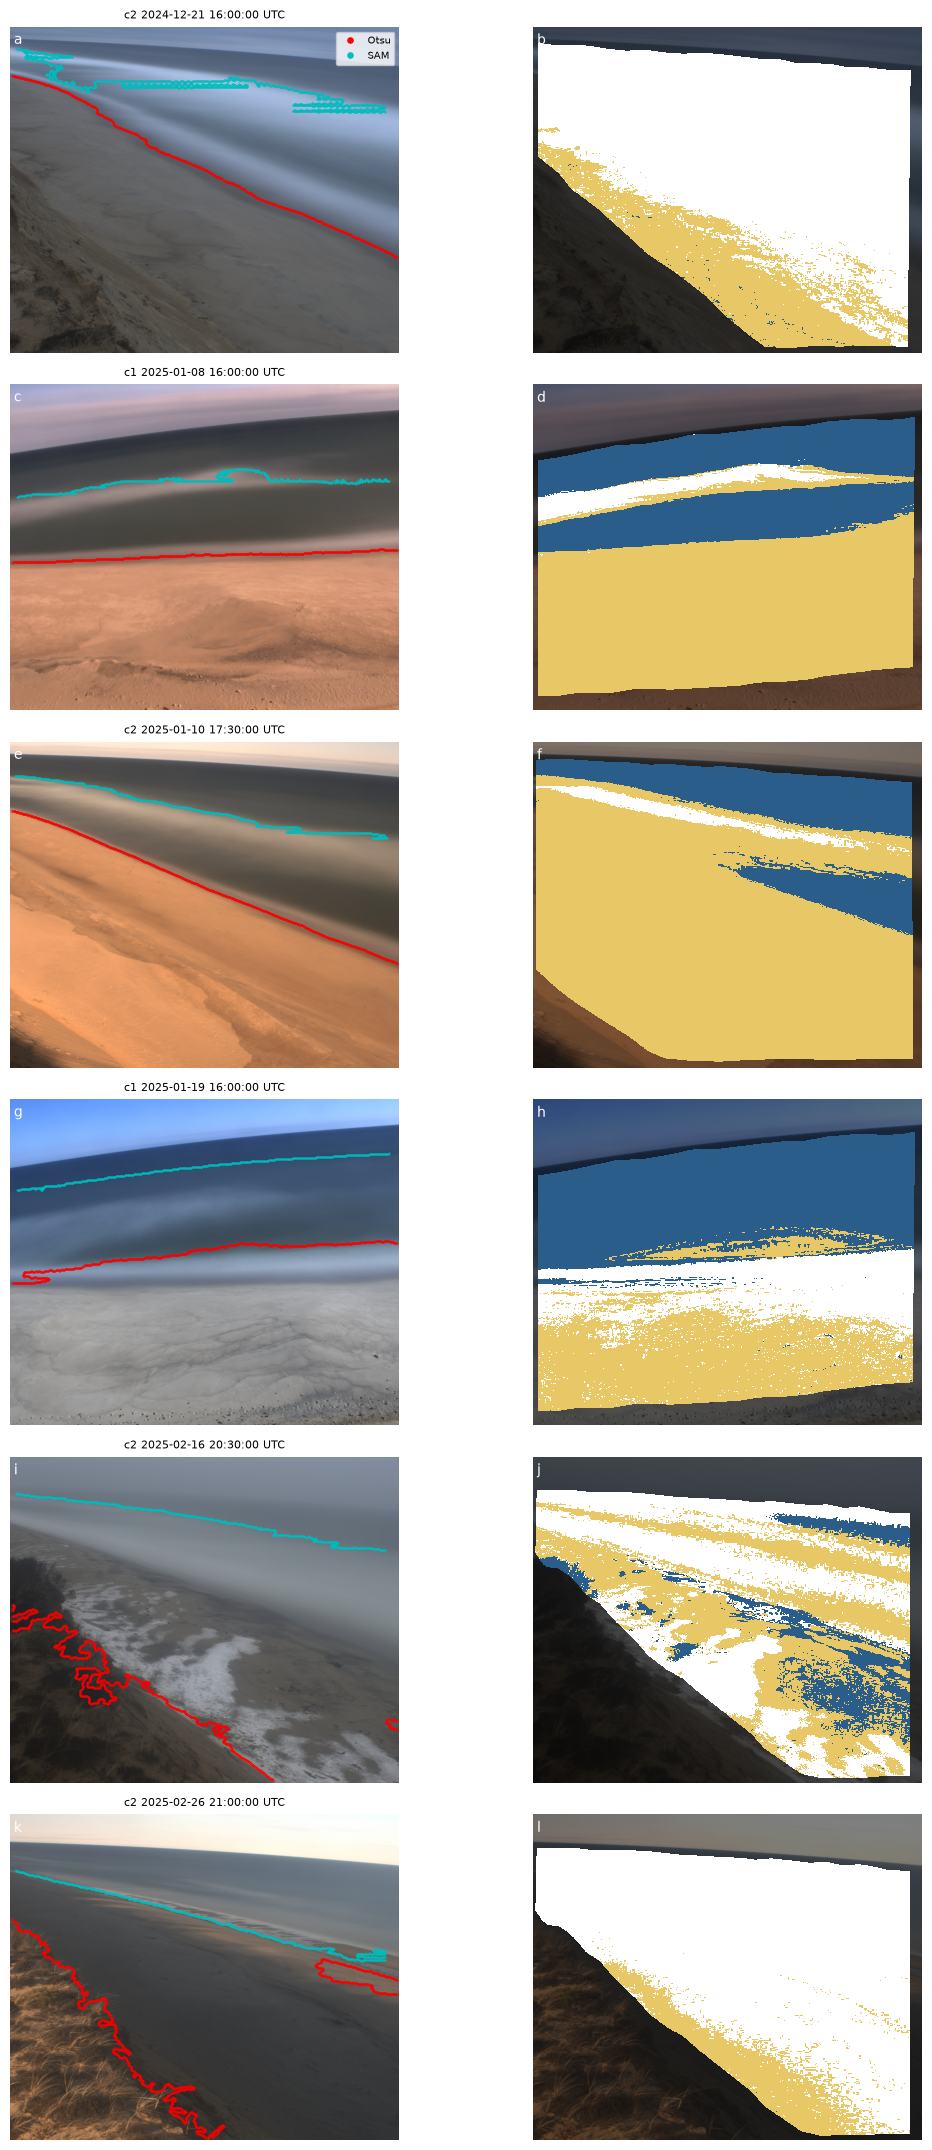

In [6]:
# classes on the labeled worst images (or the first few labeled images)
show = imgs[imgs.path.isin(worst)] if len(worst) else imgs.head(6)
fig = mc.class_figure(FIG_DIR / 'color_classes.png', show, prompts, model, ref, COLOR)

## Compare Otsu, color, and SAM with color prompts
On a random sample (the same one `qc_waterlines.ipynb` used for SAM). The distances are between methods, not
to truth; the example figure shows which is right. Rerunning appends only new images; delete
`waterlines_px_color.csv` and `waterlines_px_sam_color.csv` after changing the labels or `COLOR`.

In [7]:
cand = scan[(scan.quality > 1) & scan.path.isin(wl_px.groups)]
paths = cand.path.sample(N_TEST, random_state=1)
mc.detect_all_color(scan, WL_COLOR_CSV, prompts, model, COLOR, paths)
pred = msam.load_sam(SAM_CKPT, SAM_MODEL)
info = msam.detect_all_sam(scan, CAL_DIR, WL_SAMC_CSV, pred, msam.SAM_CFG, paths, prompts=prompts, model=model, ccfg=COLOR)
info[['sam_score', 'color_iou', 'sam_npx']].describe()

60/60  2025-03-10 14:00:00
20/60  2025-01-17 20:00:00
40/60  2025-02-17 18:00:00
60/60  2025-03-10 14:00:00


,sam_score,color_iou,sam_npx
count,60.000000,60.000000,60.000000
mean,0.935903,0.662150,1873.016667
std,0.029471,0.200846,1621.101535
min,0.853312,0.340271,1157.000000
25%,0.924528,0.466596,1188.250000
50%,0.941073,0.672827,1274.500000
75%,0.956220,0.866049,1878.250000
max,0.981422,0.986831,11015.000000


In [8]:
wl_col = pd.read_csv(WL_COLOR_CSV).groupby('path')
wl_samc = pd.read_csv(WL_SAMC_CSV).groupby('path')
sets = {'otsu': wl_px, 'color': wl_col, 'samc': wl_samc} | ({'sam': wl_sam} if wl_sam is not None else {})
ok = [p for p in paths if all(p in g.groups for g in sets.values())]
pairs = [('otsu', 'color'), ('color', 'samc'), ('otsu', 'samc')] + ([('sam', 'samc')] if wl_sam is not None else [])
d = scan[['time', 'camera', 'H0', 'water_level', 'path']].set_index('path').loc[ok]
for a, b in pairs:
    c = msam.compare_waterlines(sets[a], sets[b], ok, (a, b)).set_index('path')
    d[f'{a}_{b}'] = c[[f'd_{a}_{b}_med', f'd_{b}_{a}_med']].max(1)
d.to_csv(OUT_DIR / 'waterline_compare_color.csv', float_format='%.2f')
d[[f'{a}_{b}' for a, b in pairs]].describe().round(1)

C:\Users\csherwood\AppData\Local\Temp\1\ipykernel_61600\840939160.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  d[f'{a}_{b}'] = c[[f'd_{a}_{b}_med', f'd_{b}_{a}_med']].max(1)
C:\Users\csherwood\AppData\Local\Temp\1\ipykernel_61600\840939160.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  d[f'{a}_{b}'] = c[[f'd_{a}_{b}_med', f'd_{b}_{a}_med']].max(1)
C:\Users\csherwood\AppData\Local\Temp\1\ipykernel_61600\840939160.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  d[f'{a}_{b}'] = c[[f'd_{a}_{b}_med', f'd_{b}_{a}_med']].max(1)
C:\Users\csherwood\AppData\Local\Temp\1\ipykernel_61600\840939160.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  d[f'{a}_{b}'] = c[[f'd_{a}_{b}_med', f'd_{b}_{a}_med']].max(1)


,otsu_color,color_samc,otsu_samc,sam_samc
count,58.0,58.0,60.0,60.0
mean,391.0,356.8,109.5,83.2
std,302.8,357.2,166.8,119.2
min,4.0,4.0,2.0,2.0
25%,119.2,56.2,10.0,3.7
50%,369.7,221.9,19.8,9.1
75%,580.9,570.2,148.0,151.5
max,1386.2,1760.8,780.1,489.3


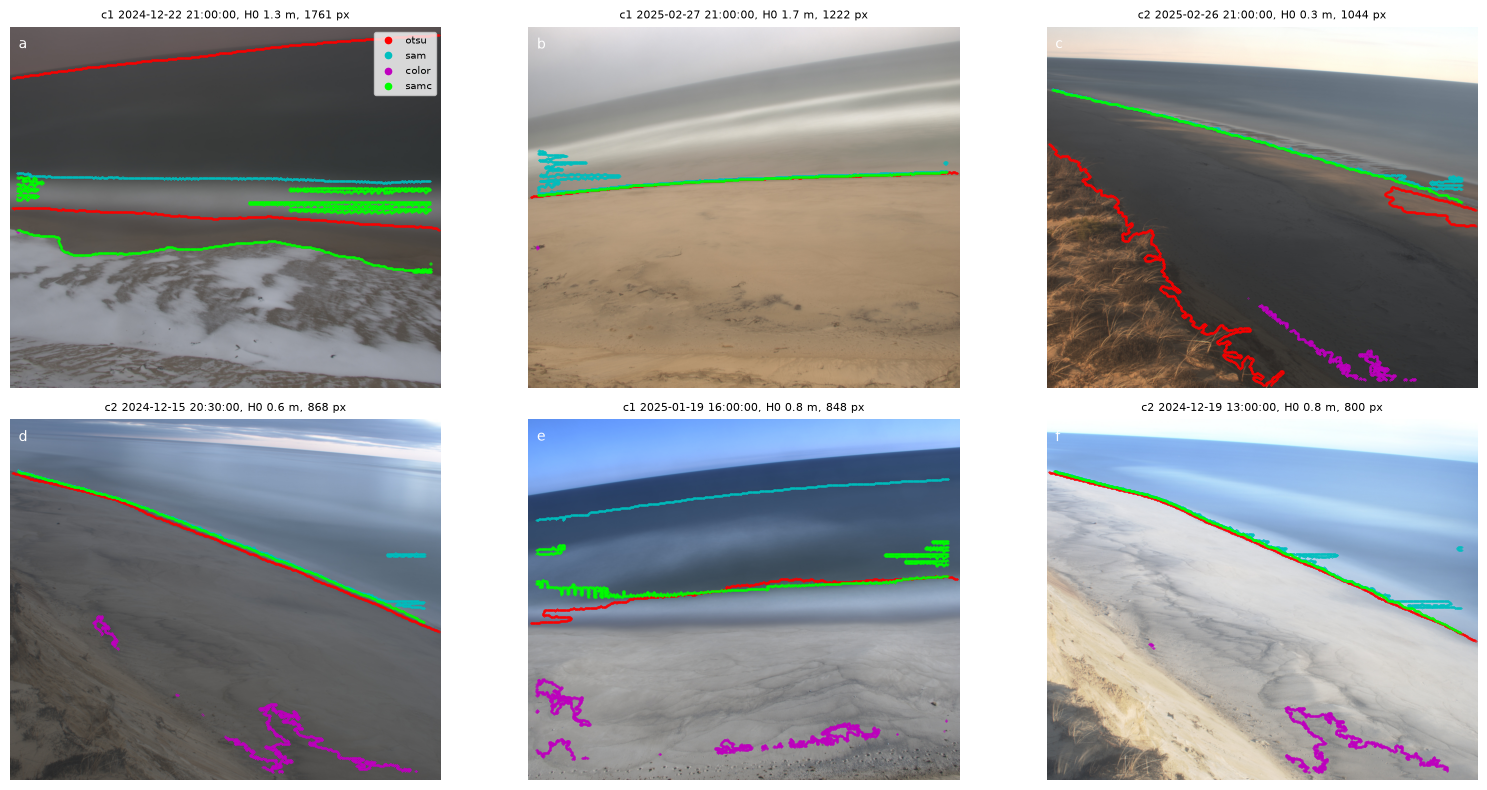

In [9]:
# the images where color and SAM-with-color disagree most, with all waterlines
ex = d.nlargest(6, 'color_samc')
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for a, (p, r), l in zip(ax.flat, ex.iterrows(), 'abcdef'):
    a.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
    for name, c in [('otsu', 'r'), ('sam', 'c'), ('color', 'm'), ('samc', 'lime')]:
        if name in sets and p in sets[name].groups:
            g = sets[name].get_group(p)
            a.plot(g.u, g.v, '.', c=c, ms=0.6, label=name)
    a.set_title(f'{r.camera} {r.time}, H0 {r.H0:.1f} m, {r.color_samc:.0f} px', fontsize=8)
    a.axis('off')
    a.text(0.02, 0.97, l, transform=a.transAxes, va='top', color='w')
ax.flat[0].legend(loc='upper right', markerscale=15, fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / 'waterline_compare_color_examples.jpg', dpi=120)

**Next:** if SAM with color prompts (`samc`) is consistently on the beach edge, run it on all images
(`paths=None`) and build DEMs from `waterlines_px_sam_color.csv` with `make_dems.ipynb`; the color waterline
(`waterlines_px_color.csv`) can be run on everything quickly for a third DEM set.

**References**
- Vos, K., Harley, M.D., Splinter, K.D., Simmons, J.A., Turner, I.L., 2019a. Sub-annual to multi-decadal
  shoreline variability from publicly available satellite imagery. *Coastal Engineering* 150, 160–174.
- Vos, K., Splinter, K.D., Harley, M.D., Simmons, J.A., Turner, I.L., 2019b. CoastSat: A Google Earth
  Engine-enabled Python toolkit to extract shorelines from publicly available satellite imagery.
  *Environmental Modelling & Software* 122, 104528.
- Kirillov, A., et al., 2023. Segment Anything. *Proceedings of the IEEE/CVF International Conference on
  Computer Vision (ICCV)*, 4015–4026.